In [1]:
%load_ext autoreload
%autoreload 2

import sys

sys.path.append("../src")   # para importar el paquete fraud desde el notebook

import numpy as np
import pandas as pd

from fraud.data import MONTH, TARGET, load_baf

df = load_baf("../data/raw/Base.csv")
print(df.shape)
print(list(df.columns))
df[TARGET].value_counts(normalize=True)

(1000000, 32)
['fraud_bool', 'income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'employment_status', 'credit_risk_score', 'email_is_free', 'housing_status', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source', 'session_length_in_minutes', 'device_os', 'keep_alive_session', 'device_distinct_emails_8w', 'device_fraud_count', 'month']


fraud_bool
0    0.988971
1    0.011029
Name: proportion, dtype: float64

In [2]:
print(df.shape, df.columns)

(1000000, 32) Index(['fraud_bool', 'income', 'name_email_similarity',
       'prev_address_months_count', 'current_address_months_count',
       'customer_age', 'days_since_request', 'intended_balcon_amount',
       'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h',
       'velocity_4w', 'bank_branch_count_8w',
       'date_of_birth_distinct_emails_4w', 'employment_status',
       'credit_risk_score', 'email_is_free', 'housing_status',
       'phone_home_valid', 'phone_mobile_valid', 'bank_months_count',
       'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source',
       'session_length_in_minutes', 'device_os', 'keep_alive_session',
       'device_distinct_emails_8w', 'device_fraud_count', 'month'],
      dtype='str')


### Tasa de fraude global y por mes

In [3]:
print("TASA DE FRAUDE GLOBAL: ", df[TARGET].mean())
por_mes = df.groupby("month")[TARGET].agg(filas="size", fraudes="sum", tasa="mean")
por_mes 

TASA DE FRAUDE GLOBAL:  0.011029


,filas,fraudes,tasa
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371
5,119323,1411,0.011825
6,108168,1450,0.013405
7,96843,1428,0.014746


### TIpos de datos y columnas constantes

In [4]:
print(df.dtypes.value_counts())
print("Columnas con 1 solo valor:", [c for c in df.columns if df[c].nunique() == 1])

int64      18
float64     9
str         5
Name: count, dtype: int64
Columnas con 1 solo valor: ['device_fraud_count']


### Valores faltantes escondidos

In [5]:
num = df.select_dtypes("number").drop(columns=[TARGET, "month"])
neg = (num < 0).sum()
neg[neg > 0].sort_values(ascending=False)

intended_balcon_amount          742523
prev_address_months_count       712920
bank_months_count               253635
credit_risk_score                14445
current_address_months_count      4254
session_length_in_minutes         2015
device_distinct_emails_8w          359
velocity_6h                         44
dtype: int64

### Fraude por grupos (Edades, estado de empleo y estado de vivienda)

In [6]:
for col in ["customer_age", "employment_status", "housing_status", "payment_type", "source"]:
    print(df.groupby(col)[TARGET].agg(filas="size", tasa="mean").round(4), "\n")

               filas    tasa
customer_age                
10             20987  0.0035
20            245855  0.0049
30            311433  0.0083
40            238712  0.0120
50            140353  0.0200
60             34770  0.0330
70              6517  0.0404
80              1297  0.0493
90                76  0.0526 

                    filas    tasa
employment_status                
CA                 730252  0.0122
CB                 138288  0.0069
CC                  37758  0.0247
CD                  26522  0.0038
CE                  22693  0.0023
CF                  44034  0.0019
CG                    453  0.0155 

                 filas    tasa
housing_status                
BA              169675  0.0375
BB              260965  0.0060
BC              372143  0.0061
BD               26161  0.0086
BE              169135  0.0034
BF                1669  0.0042
BG                 252  0.0040 

               filas    tasa
payment_type                
AA            258249  0.0053
AB 

In [7]:
for c in ["prev_address_months_count", "current_address_months_count", "bank_months_count",
          "session_length_in_minutes", "device_distinct_emails_8w", "velocity_6h", "credit_risk_score"]:
    print(c, df.loc[df[c] < 0, c].value_counts().head(3).to_dict())

prev_address_months_count {-1: 712920}
current_address_months_count {-1: 4254}
bank_months_count {-1: 253635}
session_length_in_minutes {-1.0: 2015}
device_distinct_emails_8w {-1: 359}
velocity_6h {-29.235882651923703: 1, -80.69066966650415: 1, -130.45692803910583: 1}
credit_risk_score {-1: 488, -2: 473, -3: 440}


In [8]:
import lightgbm as lgb

from fraud.data import temporal_split
from fraud.metrics import gini, ks_statistic, psi

for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].astype("category")

train, valid, test = temporal_split(df)
feats = [c for c in df.columns if c not in (TARGET, MONTH)]   # month NO es variable

model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
model.fit(train[feats], train[TARGET])

s_tr = model.predict_proba(train[feats])[:, 1]
s_va = model.predict_proba(valid[feats])[:, 1]
print("KS valid:", ks_statistic(valid[TARGET], s_va))
print("Gini valid:", gini(valid[TARGET], s_va))
print("PSI score train->valid:", psi(s_tr, s_va))

KS valid: 0.6245465272447412
Gini valid: 0.7874894652904312
PSI score train->valid: 0.004771973063573655


In [9]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=feats).sort_values(ascending=False)
print((imp / imp.sum()).head(10).round(3))

housing_status                  0.168
device_os                       0.080
name_email_similarity           0.057
current_address_months_count    0.054
credit_risk_score               0.052
bank_branch_count_8w            0.040
intended_balcon_amount          0.037
days_since_request              0.036
velocity_4w                     0.035
has_other_cards                 0.035
dtype: float64


In [10]:
from fraud.metrics import recall_at_fpr

print("Recall @ 5% FPR (valid):", recall_at_fpr(valid[TARGET], s_va))

Recall @ 5% FPR (valid): 0.5393338058114813


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from fraud.data import clean

dfc = clean(df)
train_c, valid_c, _ = temporal_split(dfc)
cat_cols = dfc[feats].select_dtypes("category").columns.tolist()
num_cols = [c for c in feats if c not in cat_cols]

pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
modelos = {
    "Regresion logistica": make_pipeline(pre, LogisticRegression(max_iter=1000)),
    "LightGBM": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
}
filas = []
for nombre, m in modelos.items():
    m.fit(train_c[feats], train_c[TARGET])
    s = m.predict_proba(valid_c[feats])[:, 1]
    filas.append({"modelo": nombre,
                  "KS": ks_statistic(valid_c[TARGET], s),
                  "Gini": gini(valid_c[TARGET], s),
                  "Recall@5%FPR": recall_at_fpr(valid_c[TARGET], s),
                  "Recall@1%FPR": recall_at_fpr(valid_c[TARGET], s, 0.01)})
pd.DataFrame(filas).round(3)

,modelo,KS,Gini,Recall@5%FPR,Recall@1%FPR
0,Regresion logistica,0.604,0.766,0.509,0.247
1,LightGBM,0.627,0.787,0.534,0.279


                              level_0                           level_1  \
344                 credit_risk_score             proposed_credit_limit   
235                      velocity_24h                       velocity_4w   
209                       velocity_6h                      velocity_24h   
112                      customer_age  date_of_birth_distinct_emails_4w   
210                       velocity_6h                       velocity_4w   
185                      zip_count_4w                       velocity_4w   
391                  phone_home_valid                phone_mobile_valid   
262                       velocity_4w  date_of_birth_distinct_emails_4w   
184                      zip_count_4w                      velocity_24h   
115                      customer_age                  phone_home_valid   
87       current_address_months_count  date_of_birth_distinct_emails_4w   
263                       velocity_4w                 credit_risk_score   
315  date_of_birth_distin

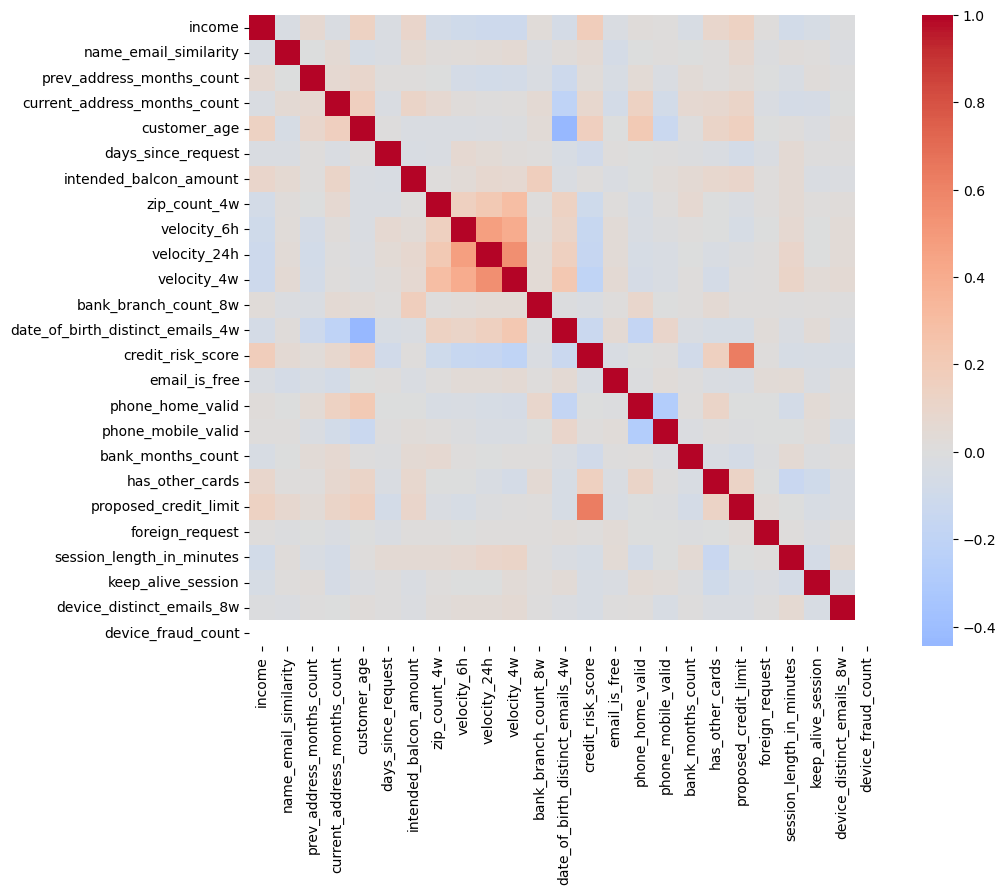

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

muestra = dfc[num_cols].sample(200_000, random_state=42)
corr = muestra.corr(method="spearman")

pares = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
         .stack().rename("rho").reset_index())
pares["abs"] = pares["rho"].abs()
print(pares.sort_values("abs", ascending=False).head(15).round(3))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.tight_layout()
plt.savefig("../reports/figures/correlaciones.png", dpi=150)

In [13]:
from sklearn.metrics import roc_auc_score

aucs = {c: roc_auc_score(train_c[TARGET], train_c[c].fillna(train_c[c].median())) for c in num_cols}
fuerza = (pd.Series(aucs) - 0.5).abs().sort_values(ascending=False)
print(fuerza.head(15).round(3))

customer_age                        0.166
credit_risk_score                   0.160
current_address_months_count        0.141
proposed_credit_limit               0.139
date_of_birth_distinct_emails_4w    0.133
income                              0.132
keep_alive_session                  0.121
name_email_similarity               0.099
bank_branch_count_8w                0.087
phone_home_valid                    0.071
has_other_cards                     0.066
email_is_free                       0.063
intended_balcon_amount              0.050
bank_months_count                   0.047
days_since_request                  0.037
dtype: float64


In [14]:
df["income"].value_counts()

income
0.9    221419
0.1    157449
0.8    146650
0.6    111973
0.7    105109
0.4     81364
0.2     69345
0.5     55858
0.3     50833
Name: count, dtype: int64

In [15]:
from sklearn.preprocessing import SplineTransformer

from fraud.features import add_features

dfe = add_features(dfc)
nuevas = ["limit_to_income", "vel_6h_vs_24h", "vel_24h_vs_4w",
          "balcon_negativo", "sin_direccion_previa", "sin_cuenta_previa"]
num_e = num_cols + nuevas
spl_cols = ["customer_age", "credit_risk_score", "current_address_months_count",
            "proposed_credit_limit", "name_email_similarity"]   # sin income
feats_e = feats + nuevas + ["income_band"]
cat_e = cat_cols + ["income_band"]
train_e, valid_e, _ = temporal_split(dfe)

def hacer_lr(numericas, categoricas, splines=()):
    resto = [c for c in numericas if c not in splines]
    partes = [("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                    StandardScaler()), resto),
              ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)]
    if splines:
        partes.append(("spl", make_pipeline(SimpleImputer(strategy="median"),
                                            SplineTransformer(n_knots=5, degree=3)), list(splines)))
    return make_pipeline(ColumnTransformer(partes), LogisticRegression(max_iter=2000))

def evaluar(nombre, modelo, tr, va, cols):
    modelo.fit(tr[cols], tr[TARGET])
    s = modelo.predict_proba(va[cols])[:, 1]
    return {"modelo": nombre, "KS": ks_statistic(va[TARGET], s), "Gini": gini(va[TARGET], s),
            "Recall@5%FPR": recall_at_fpr(va[TARGET], s),
            "Recall@1%FPR": recall_at_fpr(va[TARGET], s, 0.01)}

lgbm = lambda: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
filas = [
    evaluar("LR base", hacer_lr(num_cols, cat_cols), train_c, valid_c, feats),
    evaluar("LR + features", hacer_lr(num_e, cat_e), train_e, valid_e, feats_e),
    evaluar("LR + features + splines", hacer_lr(num_e, cat_e, spl_cols), train_e, valid_e, feats_e),
    evaluar("LightGBM base", lgbm(), train_c, valid_c, feats),
    evaluar("LightGBM + features", lgbm(), train_e, valid_e, feats_e),
]
pd.DataFrame(filas).round(3)

,modelo,KS,Gini,Recall@5%FPR,Recall@1%FPR
0,LR base,0.604,0.766,0.509,0.247
1,LR + features,0.607,0.769,0.515,0.260
2,LR + features + splines,0.619,0.782,0.523,0.285
3,LightGBM base,0.627,0.787,0.534,0.279
4,LightGBM + features,0.624,0.787,0.541,0.271


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBClassifier

xgb = lambda: XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                            colsample_bytree=0.8, tree_method="hist", enable_categorical=True,
                            random_state=42, n_jobs=-1)
rf = lambda: make_pipeline(
    ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
                        cat_cols)], remainder="passthrough"),
    RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=42))

filas2 = [
    evaluar("XGBoost base", xgb(), train_c, valid_c, feats),
    evaluar("Random Forest base", rf(), train_c, valid_c, feats),
]
pd.DataFrame(filas + filas2).round(3)

,modelo,KS,Gini,Recall@5%FPR,Recall@1%FPR
0,LR base,0.604,0.766,0.509,0.247
1,LR + features,0.607,0.769,0.515,0.260
2,LR + features + splines,0.619,0.782,0.523,0.285
3,LightGBM base,0.627,0.787,0.534,0.279
4,LightGBM + features,0.624,0.787,0.541,0.271
5,XGBoost base,0.628,0.791,0.534,0.270
6,Random Forest base,0.598,0.745,0.508,0.245


In [17]:
def bootstrap(y, s, metrica, n=200, semilla=42):
    rng = np.random.default_rng(semilla)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        vals.append(metrica(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

m_lgb = lgbm().fit(train_c[feats], train_c[TARGET])
s_lgb = m_lgb.predict_proba(valid_c[feats])[:, 1]
m_lr = hacer_lr(num_e, cat_e, spl_cols).fit(train_e[feats_e], train_e[TARGET])
s_lr = m_lr.predict_proba(valid_e[feats_e])[:, 1]

y = valid_c[TARGET].values
metricas = {"Gini": gini, "Recall@5%FPR": recall_at_fpr,
            "Recall@1%FPR": lambda a, b: recall_at_fpr(a, b, 0.01)}
for nombre, s in [("LightGBM", s_lgb), ("LR + splines", s_lr)]:
    for met, f in metricas.items():
        lo, hi = bootstrap(y, s, f)
        print(f"{nombre:13s} {met:13s} {f(y, s):.3f}  IC95% [{lo:.3f}, {hi:.3f}]")

LightGBM      Gini          0.787  IC95% [0.771, 0.803]
LightGBM      Recall@5%FPR  0.534  IC95% [0.509, 0.563]
LightGBM      Recall@1%FPR  0.279  IC95% [0.257, 0.302]
LR + splines  Gini          0.782  IC95% [0.765, 0.797]
LR + splines  Recall@5%FPR  0.523  IC95% [0.497, 0.553]
LR + splines  Recall@1%FPR  0.285  IC95% [0.262, 0.312]


In [18]:
from sklearn.metrics import confusion_matrix


def mostrar_matriz(nombre, y, s, fpr):
    umbral = np.quantile(s[y == 0], 1 - fpr)      # umbral que da ese FPR en validacion
    pred = (s >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(f"{nombre} | FPR objetivo {fpr:.0%} | umbral {umbral:.4f}")
    print(pd.DataFrame([[tn, fp], [fn, tp]], index=["real legit", "real fraude"],
                       columns=["pred legit", "pred fraude"]))
    print(f"recall {tp / (tp + fn):.3f} | precision {tp / (tp + fp):.3f} | alertas {tp + fp}\n")

modelos_val = {
    "LR base": (hacer_lr(num_cols, cat_cols), train_c, valid_c, feats),
    "LR + features": (hacer_lr(num_e, cat_e), train_e, valid_e, feats_e),
    "LR + features + splines": (hacer_lr(num_e, cat_e, spl_cols), train_e, valid_e, feats_e),
    "LightGBM base": (lgbm(), train_c, valid_c, feats),
    "LightGBM + features": (lgbm(), train_e, valid_e, feats_e),
    "XGBoost base": (xgb(), train_c, valid_c, feats),
    "Random Forest base": (rf(), train_c, valid_c, feats),
}
scores = {}
for nombre, (m, tr, va, cols) in modelos_val.items():
    m.fit(tr[cols], tr[TARGET])
    scores[nombre] = m.predict_proba(va[cols])[:, 1]

y = valid_c[TARGET].values
for nombre, s in scores.items():
    for fpr in (0.05, 0.01):
        mostrar_matriz(nombre, y, s, fpr)

LR base | FPR objetivo 5% | umbral 0.0284
             pred legit  pred fraude
real legit       112016         5896
real fraude         693          718
recall 0.509 | precision 0.109 | alertas 6614

LR base | FPR objetivo 1% | umbral 0.0820
             pred legit  pred fraude
real legit       116732         1180
real fraude        1062          349
recall 0.247 | precision 0.228 | alertas 1529

LR + features | FPR objetivo 5% | umbral 0.0281
             pred legit  pred fraude
real legit       112016         5896
real fraude         685          726
recall 0.515 | precision 0.110 | alertas 6622

LR + features | FPR objetivo 1% | umbral 0.0825
             pred legit  pred fraude
real legit       116732         1180
real fraude        1044          367
recall 0.260 | precision 0.237 | alertas 1547

LR + features + splines | FPR objetivo 5% | umbral 0.0270
             pred legit  pred fraude
real legit       112016         5896
real fraude         673          738
recall 0.523 | prec

In [19]:
# Celda 1: PSI del score por mes (referencia: meses 0 a 4)
s_all = m_lgb.predict_proba(dfc[feats])[:, 1]
d = dfc[[MONTH]].assign(score=s_all)
ref = d.loc[d[MONTH].isin(range(5)), "score"]
psi_mes = pd.Series({m: psi(ref, d.loc[d[MONTH] == m, "score"]) for m in range(8)})
print(psi_mes.round(4))

0    0.0130
1    0.0111
2    0.0080
3    0.0171
4    0.0046
5    0.0048
6    0.0008
7    0.0150
dtype: float64


,0,1,2,3,4,5,6,7
name_email_similarity,0.041,0.020,0.023,0.016,0.024,0.168,0.137,0.032
current_address_months_count,0.007,0.033,0.015,0.013,0.004,0.092,0.030,0.076
credit_risk_score,0.037,0.079,0.046,0.119,0.084,0.153,0.253,0.293
bank_branch_count_8w,0.076,0.005,0.015,0.001,0.009,0.010,0.018,0.099
intended_balcon_amount,0.022,0.006,0.006,0.003,0.019,0.032,0.026,0.041
days_since_request,0.017,0.019,0.012,0.010,0.004,0.035,0.021,0.034
velocity_4w,2.601,1.415,1.258,1.457,1.789,3.711,3.724,3.980
customer_age,0.018,0.006,0.005,0.012,0.005,0.009,0.011,0.049
income,0.001,0.005,0.023,0.005,0.018,0.018,0.088,0.069
proposed_credit_limit,0.043,0.083,0.045,0.060,0.033,0.042,0.095,0.055


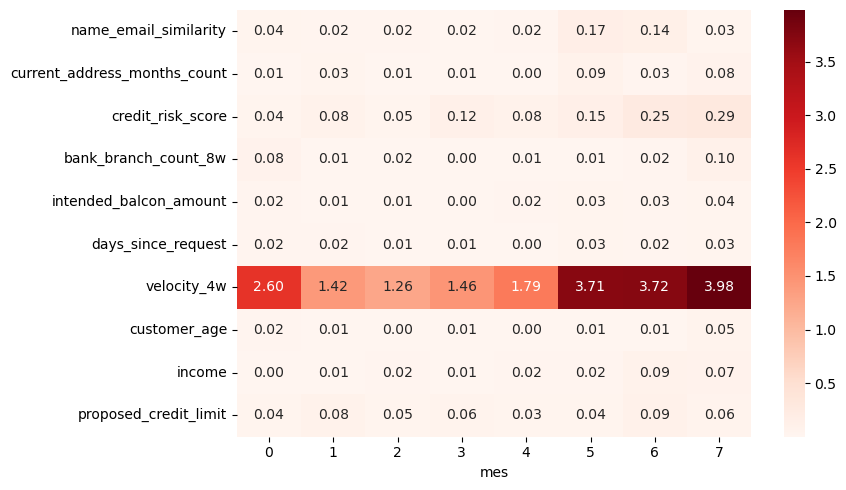

In [20]:
# Celda 2: PSI por variable y mes (mapa de calor)
vars_clave = ["name_email_similarity", "current_address_months_count", "credit_risk_score",
              "bank_branch_count_8w", "intended_balcon_amount", "days_since_request",
              "velocity_4w", "customer_age", "income", "proposed_credit_limit"]
ref_df = dfc[dfc[MONTH].isin(range(5))]
tabla = pd.DataFrame({
    m: {v: psi(ref_df[v].dropna(), dfc.loc[dfc[MONTH] == m, v].dropna()) for v in vars_clave}
    for m in range(8)
})
plt.figure(figsize=(9, 5))
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="Reds")
plt.xlabel("mes"); plt.tight_layout()
plt.savefig("../reports/figures/psi_variables_mes.png", dpi=150)
tabla.round(3)


Comportamiento **Anormal** de *velocity_4w*, miraremos su evolucion

In [24]:
dfc.groupby(MONTH)["velocity_4w"].agg(["mean", "median", "std", "min", "max"]).round(1)

,mean,median,std,min,max
month,,,,,
0,6189.2,6343.6,644.2,2995.2,6994.8
1,5392.2,5446.3,438.6,2975.5,6930.6
2,5356.3,5462.2,376.3,3004.8,6945.5
3,4913.6,4909.9,341.2,2990.7,6897.0
4,4640.2,4695.7,441.6,2996.6,6953.0
5,4284.6,4267.1,337.9,2863.8,6911.9
6,4119.2,4217.1,444.6,2825.7,6878.4
7,3343.6,3122.5,624.0,2923.0,6917.5


In [22]:
feats_sv = [c for c in feats if c != "velocity_4w"]
m_sv = lgbm().fit(train_c[feats_sv], train_c[TARGET])
s_sv = m_sv.predict_proba(valid_c[feats_sv])[:, 1]
y = valid_c[TARGET].values
print("sin velocity_4w | Gini", round(gini(y, s_sv), 3),
      "| R@5%", round(recall_at_fpr(y, s_sv), 3), "| R@1%", round(recall_at_fpr(y, s_sv, 0.01), 3))

sin velocity_4w | Gini 0.786 | R@5% 0.532 | R@1% 0.282


In [23]:
d["fraude"] = dfc[TARGET].values
cal = d[d[MONTH] <= 5].groupby(MONTH).agg(pred_media=("score", "mean"), tasa_real=("fraude", "mean"))
cal.round(4)

,pred_media,tasa_real
month,,
0,0.0108,0.0113
1,0.0088,0.0094
2,0.0082,0.0087
3,0.0107,0.0092
4,0.0114,0.0114
5,0.0085,0.0118


In [25]:
from sklearn.linear_model import LogisticRegression

# 1) modelo final, sin velocity_4w
feats_f = [c for c in feats if c != "velocity_4w"]
m_f = lgbm().fit(train_c[feats_f], train_c[TARGET])
y_v = valid_c[TARGET].values
s_v = m_f.predict_proba(valid_c[feats_f])[:, 1]

# 2) umbrales fijados SOLO con validación (FPR objetivo 5% y 1%)
thr = {f: float(np.quantile(s_v[y_v == 0], 1 - f)) for f in (0.05, 0.01)}
print("umbrales:", thr)

# 3) calibrador Platt (2 parámetros) ajustado en validación
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression(C=1e6).fit(logit(s_v), y_v)
s_v_cal = platt.predict_proba(logit(s_v))[:, 1]
print("pred media | cruda:", s_v.mean().round(4), "| calibrada:", s_v_cal.mean().round(4), "| real:", y_v.mean().round(4))

umbrales: {0.05: 0.028982847146589687, 0.01: 0.09775845826319288}
pred media | cruda: 0.0088 | calibrada: 0.0118 | real: 0.0118


/home/mayta/.conda/envs/ml-gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


                    variable  shap_abs
                   device_os    0.4069
            phone_home_valid    0.3403
              housing_status    0.3252
   prev_address_months_count    0.3073
             has_other_cards    0.2830
          keep_alive_session    0.2281
       name_email_similarity    0.2281
current_address_months_count    0.2274
               email_is_free    0.2082
                      income    0.1827
           employment_status    0.1651
      intended_balcon_amount    0.1204
                customer_age    0.1069
           bank_months_count    0.1047
        bank_branch_count_8w    0.1040


FileNotFoundError: [Errno 2] No such file or directory: 'reports/figures/shap_summary.png'

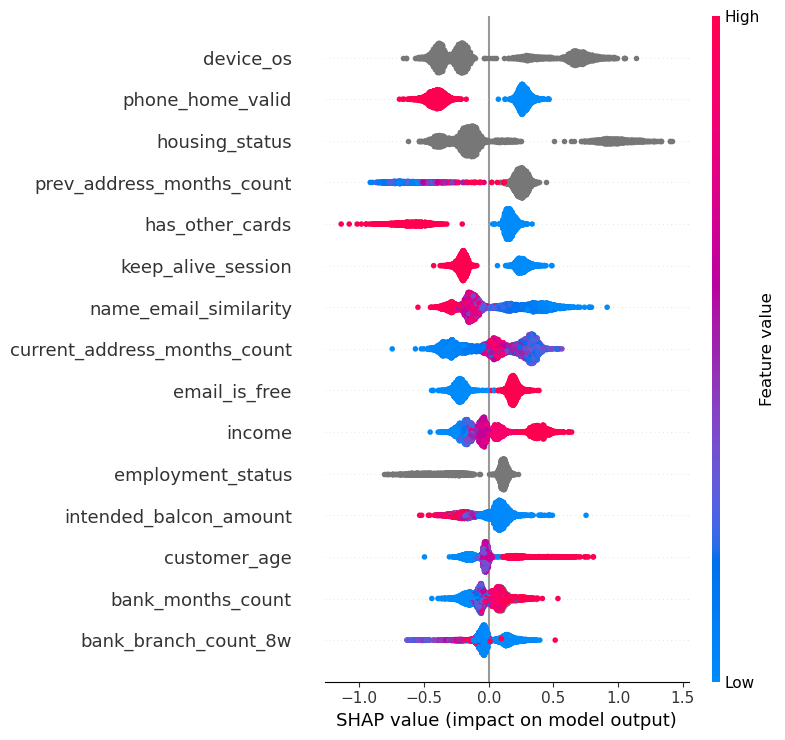

In [26]:
import matplotlib.pyplot as plt
import shap

Xs = valid_c[feats_f].sample(5000, random_state=0)
sv = shap.TreeExplainer(m_f)(Xs)
vals = sv.values[..., 1] if sv.values.ndim == 3 else sv.values   # según la versión de shap

# importancia global: promedio del valor absoluto
imp = (pd.DataFrame({"variable": feats_f, "shap_abs": np.abs(vals).mean(axis=0)})
         .sort_values("shap_abs", ascending=False))
print(imp.head(15).round(4).to_string(index=False))

# dirección y forma del efecto
shap.summary_plot(vals, Xs, max_display=15, show=False)
plt.tight_layout()
plt.savefig("reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
sv_df = pd.DataFrame(vals, columns=feats_f, index=Xs.index)
for c in ["device_os", "housing_status", "employment_status"]:
    t = (pd.DataFrame({"cat": Xs[c], "shap": sv_df[c]})
           .groupby("cat", observed=True)["shap"].agg(["mean", "count"]).round(2)
           .sort_values("mean"))
    print(c); print(t, "\n")

device_os
           mean  count
cat                   
linux     -0.40   1494
other     -0.22   1858
x11        0.24     34
macintosh  0.32    305
windows    0.71   1309 

housing_status
     mean  count
cat             
BE  -0.37   1026
BB  -0.19   1445
BF  -0.15      9
BC  -0.11   1568
BD   0.12    158
BA   0.97    794 

employment_status
     mean  count
cat             
CF  -0.55    256
CE  -0.47    130
CD  -0.28    108
CB  -0.26    567
CG  -0.23      4
CA   0.11   3766
CC   0.11    169 



In [28]:
def por_grupo(y, s, g, thr_):
    d_ = pd.DataFrame({"g": np.asarray(g), "y": y, "flag": (s >= thr_).astype(float)})
    d_["flag_leg"] = d_.flag.where(d_.y == 0)
    d_["flag_fr"] = d_.flag.where(d_.y == 1)
    return d_.groupby("g", observed=True).agg(
        n=("y", "size"), fraudes=("y", "sum"), tasa_fraude=("y", "mean"),
        flag_rate=("flag", "mean"), FPR=("flag_leg", "mean"), recall=("flag_fr", "mean")).round(3)

for col in ["customer_age", "income", "employment_status"]:
    print(col); print(por_grupo(y_v, s_v, valid_c[col], thr[0.05]), "\n")

customer_age
        n  fraudes  tasa_fraude  flag_rate    FPR  recall
g                                                        
10   2730        8        0.003      0.014  0.013   0.375
20  30471      177        0.006      0.019  0.017   0.249
30  34659      344        0.010      0.043  0.038   0.471
40  30738      412        0.013      0.063  0.057   0.500
50  15813      303        0.019      0.107  0.096   0.673
60   3833      123        0.032      0.183  0.163   0.805
70    892       37        0.041      0.197  0.173   0.757
80    178        7        0.039      0.197  0.181   0.571
90      9        0        0.000      0.000  0.000     NaN 

income
         n  fraudes  tasa_fraude  flag_rate    FPR  recall
g                                                         
0.1  16748      110        0.007      0.024  0.021   0.445
0.2   7638       45        0.006      0.025  0.024   0.267
0.3   5803       36        0.006      0.033  0.030   0.417
0.4   9510       83        0.009      0.034  

In [29]:
feats_na = [c for c in feats_f if c != "customer_age"]
m_na = lgbm().fit(train_c[feats_na], train_c[TARGET])
s_na = m_na.predict_proba(valid_c[feats_na])[:, 1]
thr_na = float(np.quantile(s_na[y_v == 0], 0.95))   # mismo FPR objetivo del 5%

print("con edad | Gini", round(gini(y_v, s_v), 3),
      "| R@5%", round(recall_at_fpr(y_v, s_v), 3), "| R@1%", round(recall_at_fpr(y_v, s_v, 0.01), 3))
print("sin edad | Gini", round(gini(y_v, s_na), 3),
      "| R@5%", round(recall_at_fpr(y_v, s_na), 3), "| R@1%", round(recall_at_fpr(y_v, s_na, 0.01), 3))
print(por_grupo(y_v, s_na, valid_c["customer_age"], thr_na))

con edad | Gini 0.786 | R@5% 0.532 | R@1% 0.282
sin edad | Gini 0.786 | R@5% 0.531 | R@1% 0.271
        n  fraudes  tasa_fraude  flag_rate    FPR  recall
g                                                        
10   2730        8        0.003      0.020  0.019   0.375
20  30471      177        0.006      0.025  0.023   0.299
30  34659      344        0.010      0.045  0.041   0.491
40  30738      412        0.013      0.069  0.063   0.507
50  15813      303        0.019      0.093  0.082   0.663
60   3833      123        0.032      0.134  0.115   0.732
70    892       37        0.041      0.133  0.116   0.541
80    178        7        0.039      0.140  0.123   0.571
90      9        0        0.000      0.000  0.000     NaN


In [30]:
# ===== EVALUACIÓN FINAL: una sola ejecución =====
test_c = dfc[dfc[MONTH].isin([6, 7])]
y_t = test_c[TARGET].values

# decidido SOLO con validación
thr_f = {f: float(np.quantile(s_na[y_v == 0], 1 - f)) for f in (0.05, 0.01)}
platt_f = LogisticRegression(C=1e6).fit(logit(s_na), y_v)

s_t = m_na.predict_proba(test_c[feats_na])[:, 1]
s_t_cal = platt_f.predict_proba(logit(s_t))[:, 1]

# 1) métricas globales + intervalos de confianza
print(f"Gini {gini(y_t, s_t):.3f} | KS {ks_statistic(y_t, s_t):.3f} | "
      f"R@5% {recall_at_fpr(y_t, s_t):.3f} | R@1% {recall_at_fpr(y_t, s_t, 0.01):.3f}")
rng = np.random.default_rng(0)
res = []
for _ in range(200):
    i = rng.integers(0, len(y_t), len(y_t))
    res.append((gini(y_t[i], s_t[i]), recall_at_fpr(y_t[i], s_t[i])))
res = np.array(res)
print("IC95% Gini", np.percentile(res[:, 0], [2.5, 97.5]).round(3),
      "| IC95% R@5%", np.percentile(res[:, 1], [2.5, 97.5]).round(3))

# 2) umbrales de validación aplicados tal cual: ¿el FPR observado se mantiene?
for f, t in thr_f.items():
    flag = s_t >= t
    tn = int(((~flag) & (y_t == 0)).sum()); fp = int((flag & (y_t == 0)).sum())
    fn = int(((~flag) & (y_t == 1)).sum()); tp = int((flag & (y_t == 1)).sum())
    print(f"FPR objetivo {f:.0%} -> FPR obs {fp/(fp+tn):.3f} | recall {tp/(tp+fn):.3f} | "
          f"precisión {tp/(tp+fp):.3f} | TP={tp} FP={fp} FN={fn} TN={tn}")

# 3) calibración
print("pred media cruda", s_t.mean().round(4), "| calibrada", s_t_cal.mean().round(4),
      "| real", y_t.mean().round(4))

# 4) mes a mes (para ver el efecto de la deriva)
for m in (6, 7):
    k = (test_c[MONTH] == m).values
    print(f"mes {m} | Gini {gini(y_t[k], s_t[k]):.3f} | R@5% {recall_at_fpr(y_t[k], s_t[k]):.3f} | "
          f"fraude real {y_t[k].mean():.4f} | pred calibrada {s_t_cal[k].mean():.4f}")

# 5) equidad por edad en test
print(por_grupo(y_t, s_t, test_c["customer_age"], thr_f[0.05]))

Gini 0.777 | KS 0.623 | R@5% 0.540 | R@1% 0.239
IC95% Gini [0.766 0.787] | IC95% R@5% [0.522 0.558]
FPR objetivo 5% -> FPR obs 0.055 | recall 0.555 | precisión 0.126 | TP=1596 FP=11107 FN=1282 TN=191026
FPR objetivo 1% -> FPR obs 0.012 | recall 0.267 | precisión 0.235 | TP=767 FP=2498 FN=2111 TN=199635
pred media cruda 0.0098 | calibrada 0.0129 | real 0.014
mes 6 | Gini 0.772 | R@5% 0.508 | fraude real 0.0134 | pred calibrada 0.0137
mes 7 | Gini 0.785 | R@5% 0.572 | fraude real 0.0147 | pred calibrada 0.0120
        n  fraudes  tasa_fraude  flag_rate    FPR  recall
g                                                        
10   5096       22        0.004      0.019  0.018   0.273
20  46341      309        0.007      0.026  0.024   0.385
30  63322      714        0.011      0.047  0.042   0.458
40  56473      844        0.015      0.076  0.069   0.586
50  25676      630        0.025      0.116  0.103   0.652
60   6464      277        0.043      0.140  0.117   0.653
70   1339       68    

FileNotFoundError: [Errno 2] No such file or directory: 'reports/figures/matriz_confusion_test.png'

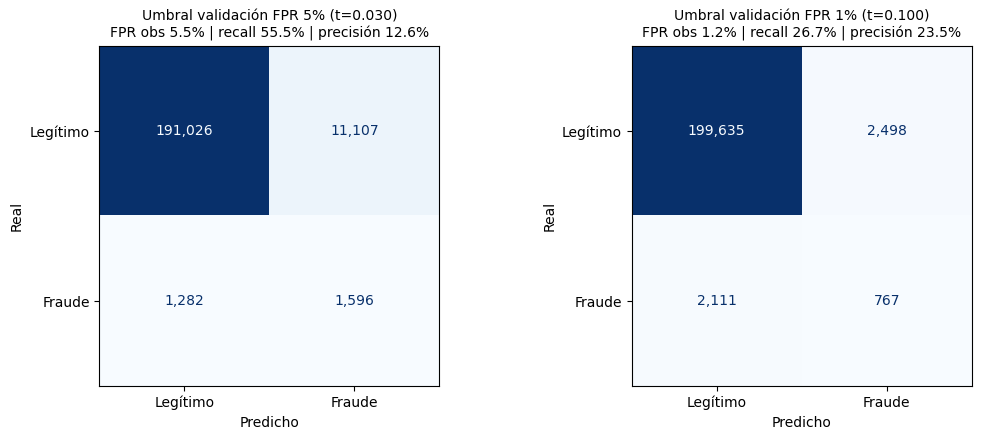

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (f, t) in zip(axes, thr_f.items()):
    pred = (s_t >= t).astype(int)
    cm = confusion_matrix(y_t, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Legítimo", "Fraude"]).plot(
        ax=ax, values_format=",d", colorbar=False, cmap="Blues")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"Umbral validación FPR {f:.0%} (t={t:.3f})\n"
                 f"FPR obs {fp/(fp+tn):.1%} | recall {tp/(tp+fn):.1%} | precisión {tp/(tp+fp):.1%}",
                 fontsize=10)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout()
plt.savefig("reports/figures/matriz_confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()